Loading Y-Net model...
Extracting intermediate features...


I0000 00:00:1785495468.658216    6844 service.cc:153] XLA service 0x75cb440577c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1785495468.658423    6844 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1785495468.799542    6844 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1785495469.491340    6844 cuda_dnn.cc:461] Loaded cuDNN version 92101
E0000 00:00:1785495471.402356    6844 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1785495481.409240    6844 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I

1/1 ━━━━━━━━━━━━━━━━━━━━ 27s 27s/step


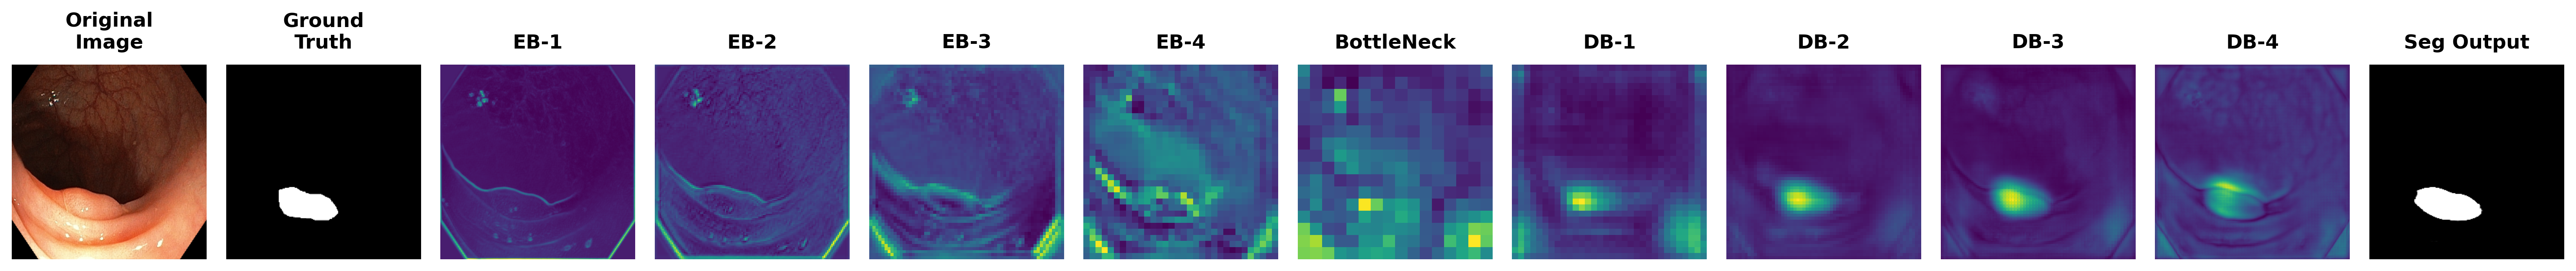

✅ Visualization saved successfully to: ./layer_by_layer_visualization.png


In [3]:
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ============================================================
# 1. Custom Layer (মডেল লোড করার জন্য এটি অপরিহার্য)
# ============================================================
@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    """Self outer-product Pairwise Correlation Coefficient (PCC) layer."""
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        epsilon = 1e-8
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(
            tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1)
        )
        return tf.keras.layers.Flatten()(pcc_matrix)

    def get_config(self):
        return super().get_config()

# ============================================================
# 2. Layer-by-Layer Visualization Function
# ============================================================
def visualize_layer_by_layer(image_path, gt_path, model_path, output_path="./layer_viz.png", img_size=256):
    print("Loading Y-Net model...")
    # মডেল লোড করা হচ্ছে
    model = tf.keras.models.load_model(
        model_path, custom_objects={"KerasPCCLayer": KerasPCCLayer}, compile=False
    )

    # আপনার কোডের name_prefix অনুযায়ী টার্গেট লেয়ারগুলোর নাম
    layer_names = [
        "enc_c1_concat",       # EB-1
        "enc_c2_concat",       # EB-2
        "enc_c3_concat",       # EB-3
        "enc_c4_concat",       # EB-4
        "shared_bottleneck_concat", # Bottleneck
        "dec_c5_concat",       # DB-1
        "dec_c6_concat",       # DB-2
        "dec_c7_concat",       # DB-3
        "dec_c8_concat",       # DB-4
        "seg_output"           # Final Segmentation Mask
    ]
    
    # এক্সট্রাক্টর মডেল তৈরি করা হচ্ছে (যা সবগুলো লেয়ারের আউটপুট একসাথে দিবে)
    outputs = [model.get_layer(name).output for name in layer_names]
    feature_extractor = tf.keras.Model(inputs=model.input, outputs=outputs)

    # ইমেজ প্রসেসিং
    raw_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (img_size, img_size))
    input_tensor = np.expand_dims(img_res / 255.0, axis=0).astype(np.float32)

    # গ্রাউন্ড ট্রুথ প্রসেসিং
    gt_gray = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
    gt_res = cv2.resize(gt_gray, (img_size, img_size))

    # মডেল থেকে সবগুলো লেয়ারের আউটপুট প্রেডিক্ট করা
    print("Extracting intermediate features...")
    features_list = feature_extractor.predict(input_tensor)

    # ============================================================
    # 3. Plotting the 1x12 Grid
    # ============================================================
    column_titles = [
        "Original\nImage", "Ground\nTruth", 
        "EB-1", "EB-2", "EB-3", "EB-4", 
        "BottleNeck", 
        "DB-1", "DB-2", "DB-3", "DB-4", 
        "Seg Output"
    ]

    fig, axes = plt.subplots(1, 12, figsize=(28, 3), dpi=300)
    plt.subplots_adjust(wspace=0.1)

    # 1. Original Image
    axes[0].imshow(img_res)
    axes[0].set_title(column_titles[0], fontsize=12, fontweight="bold", pad=10)
    
    # 2. Ground Truth
    axes[1].imshow(gt_res, cmap="gray")
    axes[1].set_title(column_titles[1], fontsize=12, fontweight="bold", pad=10)

    # 3-12. Intermediate Layers & Final Output
    for i, feature_map in enumerate(features_list):
        ax = axes[i + 2]
        
        # ফিচার ম্যাপের shape সাধারণত (1, H, W, Channels) থাকে। 
        # ভিজুয়ালাইজেশনের জন্য সবগুলো চ্যানেলের গড় (mean) নেওয়া হচ্ছে।
        f_map_2d = np.mean(feature_map[0], axis=-1)
        
        # নরমালাইজেশন
        f_map_2d = np.maximum(f_map_2d, 0)
        max_val = np.max(f_map_2d)
        if max_val > 0:
            f_map_2d /= max_val

        # ফাইনাল সেগমেন্টেশন আউটপুটের জন্য gray কালার, বাকিগুলোর জন্য viridis বা jet কালারম্যাপ
        cmap = "gray" if layer_names[i] == "seg_output" else "viridis"
        
        ax.imshow(f_map_2d, cmap=cmap)
        ax.set_title(column_titles[i + 2], fontsize=12, fontweight="bold", pad=10)

    # সবার বর্ডার/অক্ষ (axis) রিমুভ করা
    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"✅ Visualization saved successfully to: {output_path}")

# ============================================================
# Example Usage
# ============================================================
if __name__ == "__main__":
    IMAGE_PATH =  "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/104OLCV1_100H0002.jpg"
    GT_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/104OLCV1_100H0002_mask.jpg"
    MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"

    visualize_layer_by_layer(
        image_path=IMAGE_PATH,
        gt_path=GT_PATH,
        model_path=MODEL_PATH,
        output_path="./layer_by_layer_visualization.png"
    )